# Transformer - focused tuning and historical comparison

Run from top to bottom on Colab. Four configurations test the positional-weight fix,
learning rate, dropout, and Huber threshold. One seed across ten stocks means 40 fits.
Validation MAPE chooses one configuration, then that model is evaluated on the test set.

Keep the 80/10/10 split to match the rest of this project. The final table compares
new results with the original saved Transformer results from the unchanged repository,
whose average test MAPE was 1.6311%. Those old metrics are embedded below, so they
remain available in Colab without downloading another file or retraining the old model.

The old run used 70/15/15 and a longer test period. The table therefore reports a
historical difference, not a controlled estimate of improvement due to tuning.
All tuning decisions use the new validation set, not the historical or new test scores.

Completed fits are reused on rerun. Enable USE_DRIVE before starting to preserve
outputs across Colab runtime resets. Use a new RUN_NAME if the code or datasets change.
Additional evaluation seeds can be added after selection if needed.
This tuning experiment is maintained separately from the original model notebook
in models/TRANSFORMER. Repository exports are written under
tuning/TRANSFORMER/results; see transformer_tuning.md for the saved results.


In [13]:
from pathlib import Path
import json
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

if Path("/content").exists():
    REPO_ROOT = Path("/content/thesis")
    if not (REPO_ROOT / ".git").exists():
        subprocess.run(["git", "clone", "--branch", "aqsa",
                        "https://github.com/Christopher-MH/idx-stock-price-forecasting-comparison.git",
                        str(REPO_ROOT)], check=True)
else:
    REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "dataset/processed").is_dir())

DATA_DIR = REPO_ROOT / "dataset/processed"
print("Datasets:", DATA_DIR)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Datasets: /content/thesis/dataset/processed
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [14]:
# Focused search: four candidates, compared with saved historical results.
RUN_NAME = "transformer_tuning"
USE_DRIVE = False
SEEDS = [42]  # For later repeated evaluation: [42, 123, 2026, 3407, 7777]
TICKERS = ["ADRO", "BBCA", "BBNI", "BBRI", "BBTN", "BMRI", "ITMG", "MEDC", "PGAS", "PTBA"]
FEATURES = ["open", "high", "low", "close", "Volume"]
WINDOW_SIZE = 30
D_MODEL, NUM_HEADS, FF_DIM = 32, 2, 64
EPOCHS, BATCH_SIZE, PATIENCE = 100, 32, 10
TRAIN_RATIO, VALIDATION_RATIO = 0.8, 0.1

base = dict(learning_rate=5e-4, dropout=0.1, huber_delta=1.0)
CONFIGS = {
    "position_fix": base,
    "learning_rate_1e-3": {**base, "learning_rate": 1e-3},
    "dropout_0.2": {**base, "dropout": 0.2},
    "huber_0.02": {**base, "huber_delta": 0.02},
}

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = Path("/content/drive/MyDrive/idx-thesis/transformer") / RUN_NAME
else:
    OUTPUT_DIR = (Path("/content/transformer_results") if Path("/content").exists()
                  else REPO_ROOT / "tuning/TRANSFORMER/runs") / RUN_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

settings = dict(configs=CONFIGS, window=WINDOW_SIZE, d_model=D_MODEL, heads=NUM_HEADS,
                ff_dim=FF_DIM, epochs=EPOCHS, batch_size=BATCH_SIZE, patience=PATIENCE,
                train_ratio=TRAIN_RATIO, validation_ratio=VALIDATION_RATIO,
                target="unscaled_log_return", features=FEATURES, tickers=TICKERS,
                tuning_seed=SEEDS[0], tensorflow=tf.__version__)
settings_path = OUTPUT_DIR / "settings.json"
if settings_path.exists() and json.loads(settings_path.read_text()) != settings:
    raise ValueError("Settings changed. Choose a new RUN_NAME to keep results separate.")
settings_path.write_text(json.dumps(settings, indent=2))
print("Outputs:", OUTPUT_DIR)
print(f"Tuning: {len(CONFIGS)} configurations x {len(TICKERS)} stocks, seed {SEEDS[0]}")

# Saved metrics from the original committed notebook (displayed precision: six decimals).
HISTORICAL_SOURCE_COMMIT = "4f98831a56015ac1a5e49396856033994bed867d"
historical_results = pd.DataFrame([
    {'ticker': 'ADRO', 'MAE': 39.963589, 'MSE': 3358.513216, 'RMSE': 57.952681, 'MAPE': 2.109644},
    {'ticker': 'BBCA', 'MAE': 112.12632, 'MSE': 23956.498635, 'RMSE': 154.77887, 'MAPE': 1.33705},
    {'ticker': 'BBNI', 'MAE': 72.504066, 'MSE': 10348.518804, 'RMSE': 101.72767, 'MAPE': 1.705304},
    {'ticker': 'BBRI', 'MAE': 64.765273, 'MSE': 8148.899777, 'RMSE': 90.271257, 'MAPE': 1.680466},
    {'ticker': 'BBTN', 'MAE': 27.226428, 'MSE': 1362.256633, 'RMSE': 36.908761, 'MAPE': 2.510867},
    {'ticker': 'BMRI', 'MAE': 77.385013, 'MSE': 12599.588206, 'RMSE': 112.247887, 'MAPE': 1.611338},
    {'ticker': 'ITMG', 'MAE': 201.970945, 'MSE': 116964.88041, 'RMSE': 342.001287, 'MAPE': 0.887218},
    {'ticker': 'MEDC', 'MAE': 23.855187, 'MSE': 1014.266836, 'RMSE': 31.847556, 'MAPE': 1.926911},
    {'ticker': 'PGAS', 'MAE': 24.423496, 'MSE': 1126.451699, 'RMSE': 33.562653, 'MAPE': 1.456945},
    {'ticker': 'PTBA', 'MAE': 27.181005, 'MSE': 2288.73976, 'RMSE': 47.840775, 'MAPE': 1.085374},
])
historical_results.to_csv(OUTPUT_DIR / "historical_results.csv", index=False)
print(f"Historical average test MAPE: {historical_results.MAPE.mean():.4f}%")

Outputs: /content/transformer_results/transformer_tuning
Tuning: 4 configurations x 10 stocks, seed 42
Historical average test MAPE: 1.6311%


In [15]:
def load_data(ticker):
    frame = pd.read_csv(DATA_DIR / f"{ticker}.csv", parse_dates=["time"], index_col="time").sort_index()
    frame = frame[FEATURES].astype(float)
    assert not frame.index.has_duplicates and not frame.index.hasnans
    assert np.isfinite(frame.to_numpy()).all()
    assert (frame[["open", "high", "low", "close"]] > 0).all().all()
    assert (frame.Volume >= 0).all()

    train_end = int(len(frame) * TRAIN_RATIO)
    val_end = train_end + int(len(frame) * VALIDATION_RATIO)
    assert WINDOW_SIZE < train_end < val_end < len(frame)
    features = frame.copy()
    features["Volume"] = np.log1p(features.Volume)
    scaler = MinMaxScaler().fit(features.iloc[:train_end])
    scaled = scaler.transform(features).astype("float32")
    close = frame.close.to_numpy()
    returns = np.zeros(len(frame))
    returns[1:] = np.log(close[1:] / close[:-1])

    def windows(start, end):
        return {
            "X": np.stack([scaled[i-WINDOW_SIZE:i] for i in range(start, end)]),
            "y": returns[start:end, None].astype("float32"),
            "actual": close[start:end], "previous": close[start-1:end-1],
            "dates": frame.index[start:end],
        }

    # Use preceding training/validation context without skipping evaluation dates.
    return (windows(WINDOW_SIZE, train_end), windows(train_end, val_end),
            windows(val_end, len(frame)))


def evaluate(actual, predicted):
    error = predicted - actual
    assert np.isfinite(predicted).all(), "Non-finite price predictions."
    mse = float(np.mean(error ** 2))
    return {"MAE": float(np.mean(np.abs(error))), "MSE": mse,
            "RMSE": float(np.sqrt(mse)), "MAPE": float(np.mean(np.abs(error / actual)) * 100)}

In [16]:
@keras.utils.register_keras_serializable(package="IDX")
class LearnedPositionEmbedding(layers.Layer):
    def __init__(self, window, d_model, **kwargs):
        super().__init__(**kwargs)
        self.window, self.d_model = window, d_model

    def build(self, input_shape):
        self.positions = self.add_weight(name="positions", shape=(self.window, self.d_model),
                                         initializer="random_normal", trainable=True)
        super().build(input_shape)

    def call(self, inputs):
        return inputs + self.positions[None, :, :]

    def get_config(self):
        return {**super().get_config(), "window": self.window, "d_model": self.d_model}


def build_transformer(config):
    inputs = keras.Input(shape=(WINDOW_SIZE, len(FEATURES)))
    x = layers.Dense(D_MODEL)(inputs)
    x = LearnedPositionEmbedding(WINDOW_SIZE, D_MODEL, name="position_embedding")(x)
    attention = layers.MultiHeadAttention(num_heads=NUM_HEADS,
        key_dim=D_MODEL // NUM_HEADS, dropout=config["dropout"])(x, x)
    x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(config["dropout"])(attention))
    ff = layers.Dense(FF_DIM, activation="relu")(x)
    ff = layers.Dropout(config["dropout"])(ff)
    ff = layers.Dense(D_MODEL)(ff)
    x = layers.LayerNormalization(epsilon=1e-6)(x + ff)
    x = layers.Dense(32, activation="relu")(x[:, -1, :])
    outputs = layers.Dense(1)(layers.Dropout(config["dropout"])(x))
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=config["learning_rate"]),
                  loss=keras.losses.Huber(delta=config["huber_delta"]))
    return model

In [17]:
# Quick alignment and trainable-position check before tuning.
train, validation, test = load_data(TICKERS[0])
for part in (train, validation, test):
    np.testing.assert_allclose(part["previous"] * np.exp(part["y"][:, 0]),
                               part["actual"], rtol=1e-6)
keras.backend.clear_session()
keras.utils.set_random_seed(SEEDS[0])
model = build_transformer(CONFIGS["position_fix"])
position = model.get_layer("position_embedding")
before = position.positions.numpy().copy()
model.train_on_batch(train["X"][:8], train["y"][:8])
assert np.any(before != position.positions.numpy())
expected = model(validation["X"][:2], training=False).numpy()
model.save_weights(OUTPUT_DIR / "smoke.weights.h5")
keras.backend.clear_session()
keras.utils.set_random_seed(SEEDS[0])
restored = build_transformer(CONFIGS["position_fix"])
restored.optimizer.build(restored.trainable_variables)
restored.load_weights(OUTPUT_DIR / "smoke.weights.h5")
np.testing.assert_allclose(restored(validation["X"][:2], training=False).numpy(), expected, atol=1e-6)
del model, restored
keras.backend.clear_session()
print("PASSED: target alignment, trainable positions, and checkpoint reload.")

PASSED: target alignment, trainable positions, and checkpoint reload.


In [18]:
def train_configuration(name, ticker, seed):
    folder = OUTPUT_DIR / name / ticker / str(seed)
    folder.mkdir(parents=True, exist_ok=True)
    result_path = folder / "validation.csv"
    if result_path.exists():
        print(f"Cached {name}: {ticker}, seed {seed}", flush=True)
        return pd.read_csv(result_path).iloc[0].to_dict()

    train, validation, _ = load_data(ticker)
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    model = build_transformer(CONFIGS[name])
    print(f"Training {name}: {ticker}, seed {seed}", flush=True)
    history = model.fit(
        train["X"], train["y"], validation_data=(validation["X"], validation["y"]),
        epochs=EPOCHS, batch_size=BATCH_SIZE, shuffle=False, verbose=2,
        callbacks=[
            keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
            keras.callbacks.ModelCheckpoint(str(folder / "best.weights.h5"),
                monitor="val_loss", save_best_only=True, save_weights_only=True),
            keras.callbacks.CSVLogger(str(folder / "history.csv")),
            keras.callbacks.TerminateOnNaN(),
        ],
    )
    if not np.isfinite(history.history["val_loss"]).all():
        raise ValueError(f"Non-finite validation loss: {name}, {ticker}, seed {seed}")
    model.load_weights(folder / "best.weights.h5")
    predicted = validation["previous"] * np.exp(model.predict(validation["X"], verbose=0)[:, 0])
    row = {"configuration": name, "ticker": ticker, "seed": seed,
           **evaluate(validation["actual"], predicted),
           "Best Epoch": int(np.argmin(history.history["val_loss"]) + 1)}
    pd.DataFrame([row]).to_csv(result_path, index=False)
    print(f"Validation MAPE={row['MAPE']:.4f}%", flush=True)
    return row


validation_rows = []
for name in CONFIGS:
    for ticker in TICKERS:
        validation_rows.append(train_configuration(name, ticker, SEEDS[0]))
        pd.DataFrame(validation_rows).to_csv(OUTPUT_DIR / "validation_runs.csv", index=False)

ranking = pd.DataFrame(validation_rows).groupby("configuration")[["MAPE", "RMSE"]].mean()
ranking = ranking.sort_values(["MAPE", "RMSE"])
ranking.to_csv(OUTPUT_DIR / "validation_ranking.csv")
# Freeze selection before viewing either new test scores or the historical comparison.
selected = ranking.index[0]
selection_path = OUTPUT_DIR / "selected.txt"
if selection_path.exists() and selection_path.read_text() != selected:
    raise ValueError("Selection changed. Use a new RUN_NAME.")
selection_path.write_text(selected)
print(ranking.round(6).to_string(), flush=True)
print("Selected on validation:", selected, flush=True)

Training position_fix: ADRO, seed 42
Epoch 1/100
34/34 - 22s - 635ms/step - loss: 0.0564 - val_loss: 0.0152
Epoch 2/100
34/34 - 2s - 64ms/step - loss: 0.0265 - val_loss: 0.0103
Epoch 3/100
34/34 - 0s - 9ms/step - loss: 0.0095 - val_loss: 0.0016
Epoch 4/100
34/34 - 0s - 8ms/step - loss: 0.0056 - val_loss: 0.0015
Epoch 5/100
34/34 - 0s - 9ms/step - loss: 0.0030 - val_loss: 0.0014
Epoch 6/100
34/34 - 0s - 9ms/step - loss: 0.0019 - val_loss: 0.0012
Epoch 7/100
34/34 - 0s - 8ms/step - loss: 0.0015 - val_loss: 0.0012
Epoch 8/100
34/34 - 0s - 9ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 9/100
34/34 - 0s - 9ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 10/100
34/34 - 0s - 9ms/step - loss: 0.0010 - val_loss: 0.0011
Epoch 11/100
34/34 - 0s - 9ms/step - loss: 9.4146e-04 - val_loss: 0.0011
Epoch 12/100
34/34 - 0s - 8ms/step - loss: 7.9930e-04 - val_loss: 0.0011
Epoch 13/100
34/34 - 0s - 9ms/step - loss: 7.2883e-04 - val_loss: 0.0011
Epoch 14/100
34/34 - 0s - 6ms/step - loss: 5.9849e-04 - val

Validation MAPE=2.0788%
Training position_fix: BBRI, seed 42
Epoch 1/100
34/34 - 13s - 387ms/step - loss: 0.0474 - val_loss: 0.0041
Epoch 2/100
34/34 - 0s - 11ms/step - loss: 0.0157 - val_loss: 0.0031
Epoch 3/100
34/34 - 0s - 13ms/step - loss: 0.0064 - val_loss: 0.0010
Epoch 4/100
34/34 - 1s - 16ms/step - loss: 0.0039 - val_loss: 7.0745e-04
Epoch 5/100
34/34 - 0s - 12ms/step - loss: 0.0022 - val_loss: 5.3095e-04
Epoch 6/100
34/34 - 0s - 12ms/step - loss: 0.0016 - val_loss: 4.4247e-04
Epoch 7/100
34/34 - 0s - 9ms/step - loss: 0.0012 - val_loss: 4.2923e-04
Epoch 8/100
34/34 - 0s - 10ms/step - loss: 8.2156e-04 - val_loss: 3.7168e-04
Epoch 9/100
34/34 - 0s - 6ms/step - loss: 8.5435e-04 - val_loss: 3.7357e-04
Epoch 10/100
34/34 - 0s - 8ms/step - loss: 6.3021e-04 - val_loss: 3.5462e-04
Epoch 11/100
34/34 - 0s - 6ms/step - loss: 5.8776e-04 - val_loss: 3.7223e-04
Epoch 12/100
34/34 - 0s - 6ms/step - loss: 5.0125e-04 - val_loss: 3.6971e-04
Epoch 13/100
34/34 - 0s - 6ms/step - loss: 4.5739e-04 -

In [19]:
# Evaluate only the selected model. The old model's results are already saved.
selected = (OUTPUT_DIR / "selected.txt").read_text()
test_rows = []
for ticker in TICKERS:
    _, _, test = load_data(ticker)
    naive = evaluate(test["actual"], test["previous"])
    for seed in SEEDS:
        train_configuration(selected, ticker, seed)  # Cached for the tuning seed.
        folder = OUTPUT_DIR / selected / ticker / str(seed)
        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)
        model = build_transformer(CONFIGS[selected])
        model.optimizer.build(model.trainable_variables)
        model.load_weights(folder / "best.weights.h5")
        predicted = test["previous"] * np.exp(model.predict(test["X"], verbose=0)[:, 0])
        row = {"configuration": selected, "ticker": ticker, "seed": seed,
               **evaluate(test["actual"], predicted), "Naive MAPE": naive["MAPE"]}
        test_rows.append(row)
        pd.DataFrame({"time": test["dates"], "actual": test["actual"],
                      "predicted": predicted, "naive": test["previous"]}).to_csv(
                          folder / "test_predictions.csv", index=False)
        pd.DataFrame(test_rows).to_csv(OUTPUT_DIR / "test_runs.csv", index=False)

test_results = pd.DataFrame(test_rows)

def compare_with_history(new_results):
    latest = new_results.groupby("ticker")[["MAE", "MSE", "RMSE", "MAPE", "Naive MAPE"]].mean()
    old = historical_results.set_index("ticker").reindex(latest.index)
    assert old[["MAE", "MSE", "RMSE", "MAPE"]].notna().all().all(), "Missing historical ticker."
    table = pd.DataFrame({"Old MAPE": old.MAPE, "New MAPE": latest.MAPE,
                          "Old RMSE": old.RMSE, "New RMSE": latest.RMSE,
                          "New Naive MAPE": latest["Naive MAPE"]})
    # Positive change means the new error is lower, across different test periods.
    table["MAPE Reduction (%)"] = (1 - table["New MAPE"] / table["Old MAPE"]) * 100
    table["RMSE Reduction (%)"] = (1 - table["New RMSE"] / table["Old RMSE"]) * 100
    return table

comparison = compare_with_history(test_results)
comparison.to_csv(OUTPUT_DIR / "historical_vs_tuned.csv")
print(comparison.round(4).to_string())
before, after = comparison["Old MAPE"].mean(), comparison["New MAPE"].mean()
print(f"\nHistorical average MAPE: {before:.4f}% | New average MAPE: {after:.4f}%")
print(f"Historical relative MAPE reduction: {(1 - after / before) * 100:.2f}%")
print("Different test periods: old 70/15/15, new 80/10/10. This is a historical comparison.")
if len(SEEDS) > 1:
    print("\nNew test MAPE mean/std across seed-level averages:")
    print(test_results.groupby("seed").MAPE.mean().agg(["mean", "std"]).round(4).to_string())

Cached learning_rate_1e-3: ADRO, seed 42
Cached learning_rate_1e-3: BBCA, seed 42
Cached learning_rate_1e-3: BBNI, seed 42
Cached learning_rate_1e-3: BBRI, seed 42
Cached learning_rate_1e-3: BBTN, seed 42
Cached learning_rate_1e-3: BMRI, seed 42
Cached learning_rate_1e-3: ITMG, seed 42
Cached learning_rate_1e-3: MEDC, seed 42
Cached learning_rate_1e-3: PGAS, seed 42
Cached learning_rate_1e-3: PTBA, seed 42
        Old MAPE  New MAPE  Old RMSE  New RMSE  New Naive MAPE  MAPE Reduction (%)  RMSE Reduction (%)
ticker                                                                                                
ADRO      2.1096    1.7417   57.9527   45.8165          1.7167             17.4423             20.9416
BBCA      1.3370    1.1886  154.7789  130.0531          1.1967             11.1045             15.9749
BBNI      1.7053    1.3435  101.7277   79.9529          1.3422             21.2185             21.4050
BBRI      1.6805    1.3703   90.2713   70.3394          1.3568             

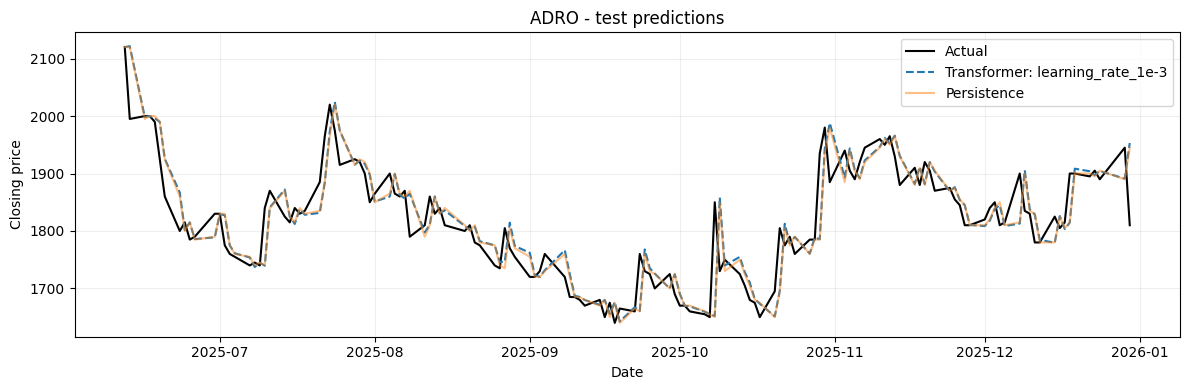

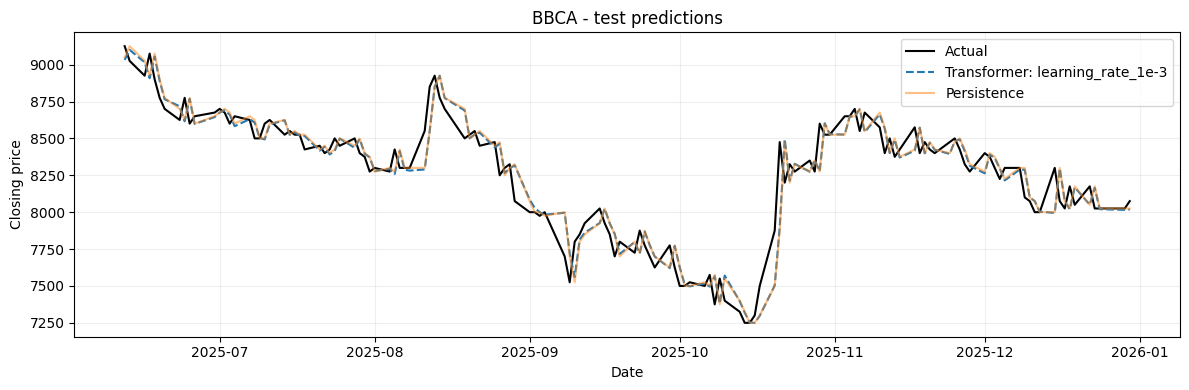

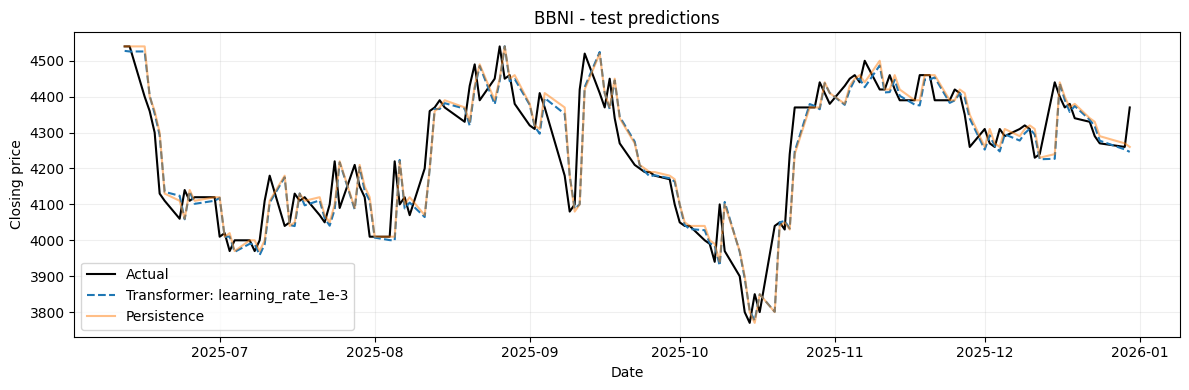

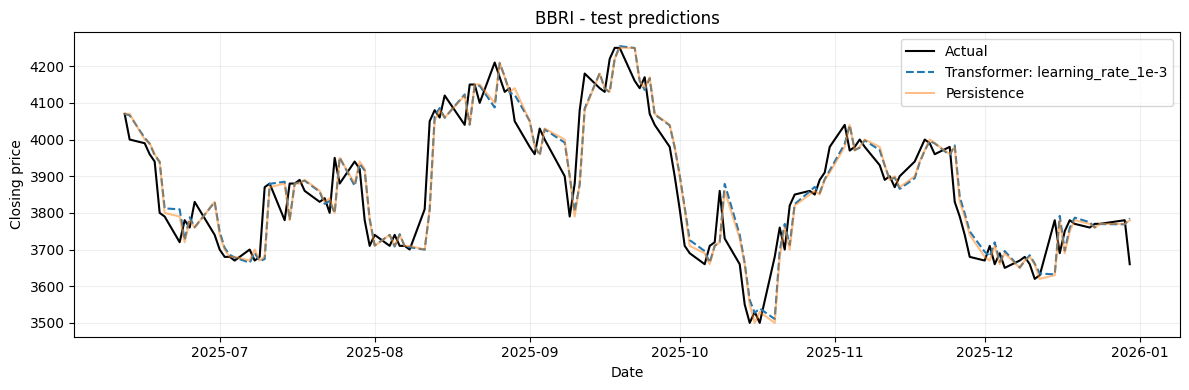

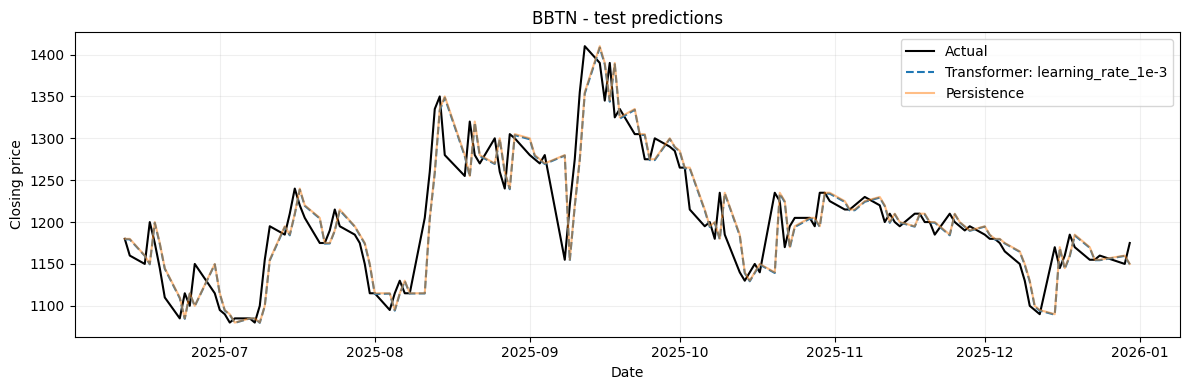

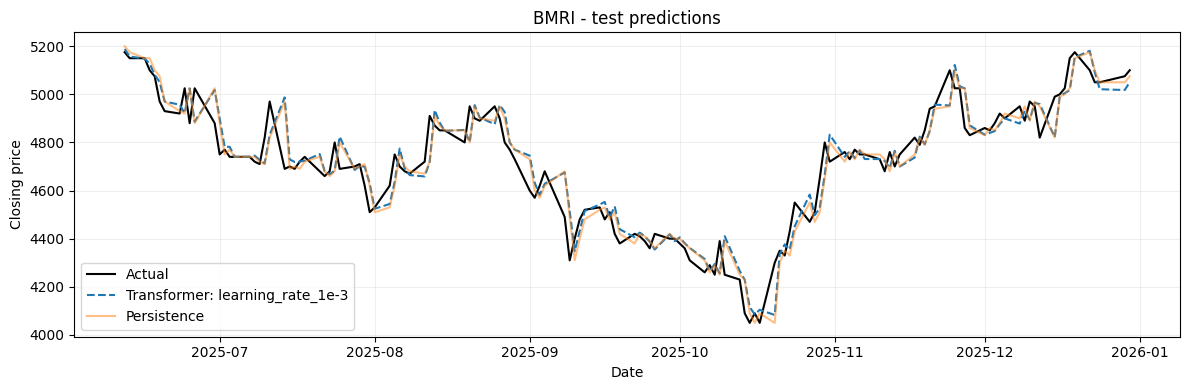

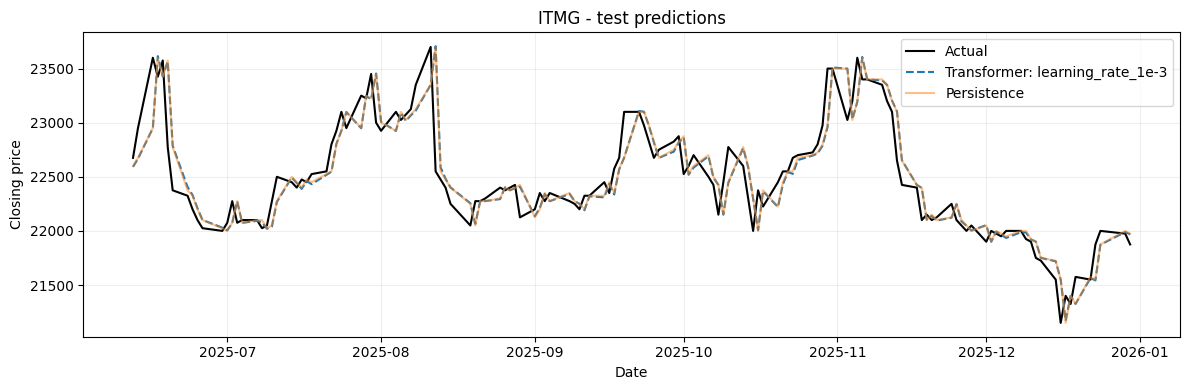

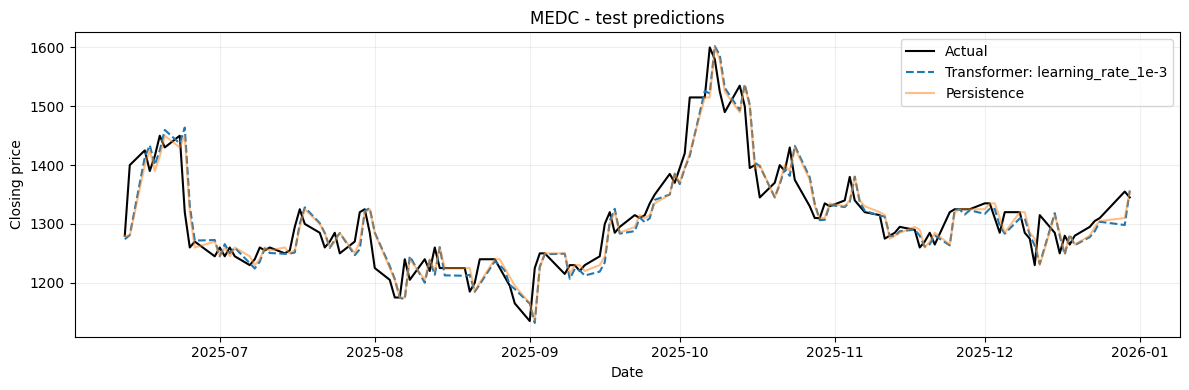

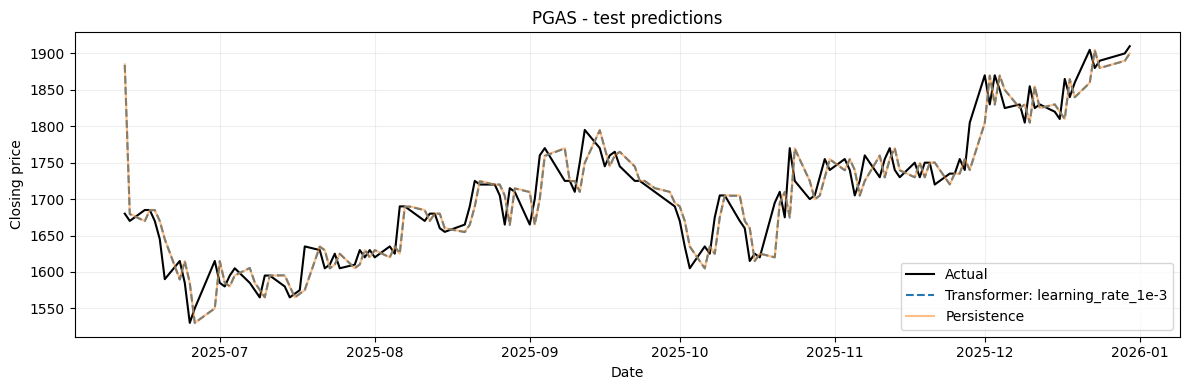

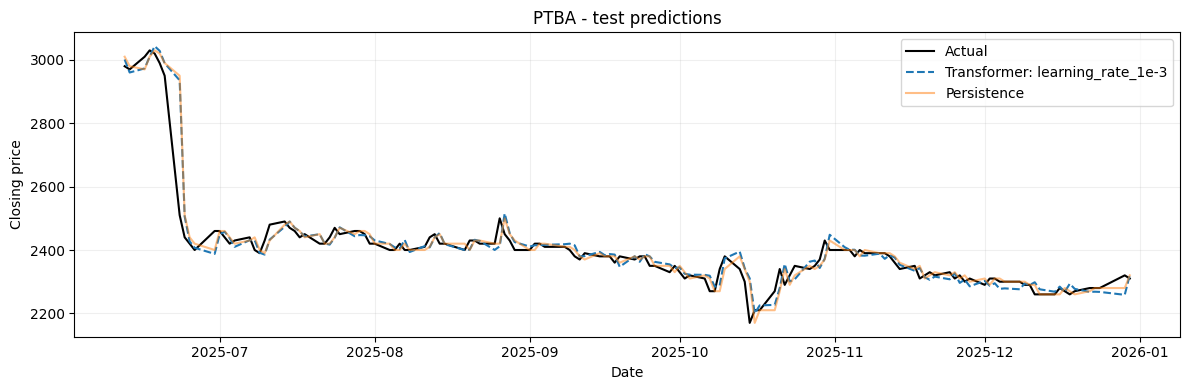

In [20]:
# Latest test predictions; the historical reference contains metrics, not prediction data.
for ticker in TICKERS:
    predictions = pd.read_csv(
        OUTPUT_DIR / selected / ticker / str(SEEDS[0]) / "test_predictions.csv", parse_dates=["time"])
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(predictions.time, predictions.actual, label="Actual", color="black")
    ax.plot(predictions.time, predictions.predicted, label=f"Transformer: {selected}", linestyle="--")
    ax.plot(predictions.time, predictions.naive, label="Persistence", alpha=0.5)
    ax.set(title=f"{ticker} - test predictions", xlabel="Date", ylabel="Closing price")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{ticker}_predictions.png", dpi=150)
    plt.show()
    plt.close(fig)

## Export files for the repository

Run the cell below after evaluation. If this Colab runtime already completed training,
run only this new cell; it reads the saved run CSVs without retraining.

It writes the standard evaluation CSV, prediction CSVs and PNGs for every stock
under tuning/TRANSFORMER/results/,
training-loss PNGs, tuning CSVs and a tuning comparison PNG. The historical comparison
is exported separately, and the original Transformer_evaluation (fix).csv is preserved.
The evaluation CSV averages per-seed metrics if more than one seed is used; the
prediction plots show the first seed, and the prediction CSVs retain every seed.

Download transformer_outputs.zip from the printed runtime path and extract it into
the local repository root. All exported files in the ZIP use paths under tuning/TRANSFORMER/results/.


In [ ]:
# Export existing results only: no fitting or model loading.
def export_transformer_outputs(run_dir, repo_root, seeds):
    import json
    import zipfile
    from pathlib import Path
    import pandas as pd
    import matplotlib.pyplot as plt

    run_dir, repo_root = Path(run_dir), Path(repo_root)
    saved = json.loads((run_dir / "settings.json").read_text())
    selected_name = (run_dir / "selected.txt").read_text().strip()
    tickers, metrics = saved["tickers"], ["MAE", "MSE", "RMSE", "MAPE"]
    validation = pd.read_csv(run_dir / "validation_runs.csv")
    tests = pd.read_csv(run_dir / "test_runs.csv")
    historical = pd.read_csv(run_dir / "historical_results.csv").set_index("ticker")

    # Reject incomplete runs before writing the repository exports.
    expected_tests = {(ticker, seed) for ticker in tickers for seed in seeds}
    if (tests.duplicated(["ticker", "seed"]).any()
            or set(zip(tests.ticker, tests.seed)) != expected_tests
            or set(tests.configuration) != {selected_name}):
        raise ValueError("Test results are incomplete. Finish the test-evaluation cell first.")
    expected_validation = {(name, ticker, saved["tuning_seed"])
                           for name in saved["configs"] for ticker in tickers}
    if (validation.duplicated(["configuration", "ticker", "seed"]).any()
            or set(zip(validation.configuration, validation.ticker, validation.seed))
            != expected_validation):
        raise ValueError("Validation results are incomplete. Finish the search cell first.")
    for ticker, seed in expected_tests:
        folder = run_dir / selected_name / ticker / str(seed)
        for filename in ("test_predictions.csv", "history.csv"):
            if not (folder / filename).is_file():
                raise FileNotFoundError(folder / filename)

    exported = []
    def destination(relative):
        target = repo_root / relative
        target.parent.mkdir(parents=True, exist_ok=True)
        exported.append(target)
        return target

    def parameters(name):
        cfg = saved["configs"][name]
        return (f"config={name}, window={saved['window']}, d_model={saved['d_model']}, "
                f"heads={saved['heads']}, ff_dim={saved['ff_dim']}, "
                f"learning_rate={cfg['learning_rate']}, dropout={cfg['dropout']}, "
                f"huber_delta={cfg['huber_delta']}, target={saved['target']}")

    # Match the other models exactly; repeated seeds use mean per-run metrics.
    evaluation = tests.groupby("ticker")[metrics].mean().reindex(tickers).reset_index()
    evaluation["model"] = "TRANSFORMER"
    evaluation["parameter"] = parameters(selected_name)
    evaluation[["ticker", "model", *metrics, "parameter"]].to_csv(
        destination("tuning/TRANSFORMER/results/TRANSFORMER_evaluation.csv"), index=False)
    runs = tests.assign(model="TRANSFORMER", parameter=parameters(selected_name), split="test")
    runs.to_csv(destination("tuning/TRANSFORMER/results/TRANSFORMER_runs.csv"), index=False)

    # Preserve the historical comparison separately from the standard evaluation.
    comparison = evaluation.set_index("ticker")[metrics].add_prefix("New ").join(
        historical[metrics].add_prefix("Old "))
    comparison["New Naive MAPE"] = tests.groupby("ticker")["Naive MAPE"].mean()
    for metric in ("MAPE", "RMSE"):
        comparison[f"{metric} Reduction (%)"] = (
            1 - comparison[f"New {metric}"] / comparison[f"Old {metric}"]) * 100
    comparison["Old split"] = "70/15/15"
    comparison["New split"] = "80/10/10"
    comparison["Comparison"] = "Historical results on different test periods"
    comparison.to_csv(destination("tuning/TRANSFORMER/results/TRANSFORMER_historical_comparison.csv"))

    # Same tuning CSV/average/bar-chart organization as ARIMA and SARIMA.
    tuning = validation.rename(columns={"configuration": "config"}).copy()
    for key in ("learning_rate", "dropout", "huber_delta"):
        tuning[key] = tuning["config"].map(lambda name: saved["configs"][name][key])
    tuning["parameter"] = tuning["config"].map(parameters)
    tuning["split"] = "validation"
    tuning.to_csv(destination("tuning/TRANSFORMER/results/transformer_tuning.csv"), index=False)
    averages = tuning.groupby("config")[metrics].mean().round(4).reset_index()
    averages.to_csv(destination("tuning/TRANSFORMER/results/transformer_tuning_averages.csv"),
                    index=False)
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
    for ax, metric in zip(axes.flat, metrics):
        ax.bar(averages["config"], averages[metric], color="steelblue")
        ax.set(title=metric, xlabel="Configuration", ylabel=metric)
        ax.tick_params(axis="x", labelrotation=20)
        ax.grid(axis="y", alpha=0.2)
    fig.suptitle(f"Transformer validation tuning - selected: {selected_name}")
    fig.savefig(destination("tuning/TRANSFORMER/results/transformer_tuning_comparison.png"),
                dpi=150)
    plt.close(fig)

    for ticker in tickers:
        prediction_runs = []
        fig_loss, ax_loss = plt.subplots(figsize=(10, 4), constrained_layout=True)
        for seed in seeds:
            folder = run_dir / selected_name / ticker / str(seed)
            predictions = pd.read_csv(folder / "test_predictions.csv", parse_dates=["time"])
            prediction_runs.append(predictions.assign(seed=seed))
            history = pd.read_csv(folder / "history.csv")
            ax_loss.plot(history.epoch + 1, history.loss, label=f"Train, seed {seed}")
            ax_loss.plot(history.epoch + 1, history.val_loss,
                         linestyle="--", label=f"Validation, seed {seed}")
        pd.concat(prediction_runs, ignore_index=True).to_csv(
            destination(f"tuning/TRANSFORMER/results/predictions/{ticker}.csv"), index=False)
        ax_loss.set(title=f"{ticker} - Transformer loss", xlabel="Epoch", ylabel="Huber loss")
        ax_loss.legend()
        ax_loss.grid(alpha=0.2)
        fig_loss.savefig(destination(f"tuning/TRANSFORMER/results/plots/training/{ticker}.png"), dpi=150)
        plt.close(fig_loss)

        # A single saved seed is plotted, rather than averaging predictions into an ensemble.
        predictions = prediction_runs[0]
        fig, ax = plt.subplots(figsize=(14, 6), constrained_layout=True)
        source = repo_root / "dataset/processed" / f"{ticker}.csv"
        if source.exists():
            frame = pd.read_csv(source, parse_dates=["time"]).sort_values("time")
            context = frame.loc[frame.time < predictions.time.iloc[0]].tail(saved["window"])
            actual = pd.concat([context[["time", "close"]].rename(columns={"close": "actual"}),
                                predictions[["time", "actual"]]], ignore_index=True)
        else:
            actual = predictions
        ax.plot(actual.time, actual.actual, label="Actual", color="black", linewidth=1)
        ax.plot(predictions.time, predictions.predicted, label="Predicted", color="red",
                linewidth=1.5, linestyle="--")
        ax.axvline(predictions.time.iloc[0], color="blue", linestyle=":", alpha=0.5,
                   label="Test start")
        ax.set(title=f"{ticker} - Transformer ({selected_name}, seed {seeds[0]})",
               xlabel="Date", ylabel="Closing price")
        ax.legend()
        ax.grid(alpha=0.2)
        fig.savefig(destination(f"tuning/TRANSFORMER/results/plots/{ticker}.png"), dpi=150)
        plt.close(fig)

    # Extract this archive into the local repository to retain these relative paths.
    archive = run_dir / "transformer_outputs.zip"
    with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
        for target in exported:
            bundle.write(target, arcname=target.relative_to(repo_root).as_posix())
    print(f"Exported {len(exported)} files under {repo_root}")
    print("Evaluation:", repo_root / "tuning/TRANSFORMER/results/TRANSFORMER_evaluation.csv")
    print("Tuning:", repo_root / "tuning/TRANSFORMER/results")
    print("Download ZIP:", archive)
    return archive


export_archive = export_transformer_outputs(OUTPUT_DIR, REPO_ROOT, SEEDS)
